Training data shape: (120, 4)
Testing data shape: (30, 4)

Hidden Layers: [8], Activation: relu
Test Accuracy: 0.7667
Test Loss: 0.4049

Hidden Layers: [8], Activation: tanh
Test Accuracy: 0.8000
Test Loss: 0.4002

Hidden Layers: [8], Activation: sigmoid
Test Accuracy: 0.8000
Test Loss: 0.5597

Hidden Layers: [16, 8], Activation: relu
Test Accuracy: 0.9333
Test Loss: 0.1386

Hidden Layers: [16, 8], Activation: tanh
Test Accuracy: 0.9000
Test Loss: 0.2161

Hidden Layers: [16, 8], Activation: sigmoid
Test Accuracy: 0.8000
Test Loss: 0.4992

Hidden Layers: [32, 16, 8], Activation: relu
Test Accuracy: 0.9333
Test Loss: 0.0973

Hidden Layers: [32, 16, 8], Activation: tanh
Test Accuracy: 0.9333
Test Loss: 0.1203

Hidden Layers: [32, 16, 8], Activation: sigmoid
Test Accuracy: 0.8000
Test Loss: 0.5084

Best Model Configuration:
Hidden Layers: [16, 8]
Activation: relu
Best Test Accuracy: 0.9333


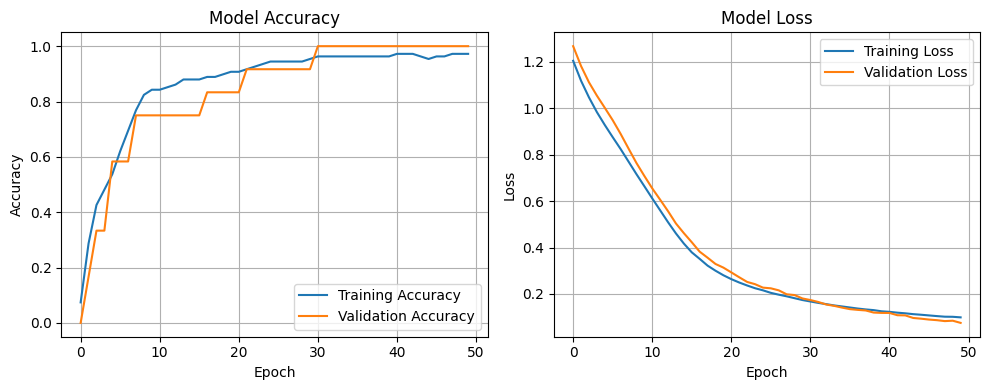


Sample Flower Measurements: [5.1 3.5 1.4 0.2]
Predicted Iris Species: setosa
Prediction Probabilities: [0.9967 0.0021 0.0012]


In [ ]:
# ==========================================
# Exp-2: Multi-Layer Perceptron (MLP) for Classification
# ==========================================

# Step 1: Import Necessary Libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Step 2: Load and Preprocess the Dataset
iris = load_iris()

X = iris.data
y = iris.target
classes = iris.target_names

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Step 3: Create the MLP Model
def create_mlp(hidden_layers, activation):
    model = Sequential()
    model.add(Input(shape=(4,)))

    for units in hidden_layers:
        model.add(Dense(units, activation=activation))

    model.add(Dense(3, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Step 4: Train and Evaluate Different MLP Configurations
hidden_layer_configs = [
    [8],
    [16, 8],
    [32, 16, 8]
]

activations = ["relu", "tanh", "sigmoid"]

best_accuracy = 0
best_model = None
best_history = None
best_config = None

for hidden_layers in hidden_layer_configs:
    for activation in activations:

        print(
            f"\nHidden Layers: {hidden_layers}, "
            f"Activation: {activation}"
        )

        model = create_mlp(hidden_layers, activation)

        history = model.fit(
            X_train,
            y_train,
            epochs=50,
            batch_size=8,
            validation_split=0.1,
            verbose=0
        )

        test_loss, test_accuracy = model.evaluate(
            X_test, y_test, verbose=0
        )

        print(f"Test Accuracy: {test_accuracy:.4f}")
        print(f"Test Loss: {test_loss:.4f}")

        if test_accuracy > best_accuracy:
            best_accuracy = test_accuracy
            best_model = model
            best_history = history
            best_config = (hidden_layers, activation)

# Step 5: Display Best Model Performance
print("\nBest Model Configuration:")
print("Hidden Layers:", best_config[0])
print("Activation:", best_config[1])
print(f"Best Test Accuracy: {best_accuracy:.4f}")

# Step 6: Visualize Training Accuracy and Loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(best_history.history["loss"], label="Training Loss")
plt.plot(best_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Step 7: Predict a New Iris Flower
# Sample measurements: sepal length, sepal width,
# petal length, petal width (in cm)
sample_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

# Scale the sample using the fitted scaler
sample_scaled = scaler.transform(sample_flower)

# Predict the species
prediction = best_model.predict(sample_scaled, verbose=0)
predicted_class = np.argmax(prediction, axis=1)[0]

print("\nSample Flower Measurements:", sample_flower[0])
print("Predicted Iris Species:", classes[predicted_class])
print("Prediction Probabilities:", np.round(prediction[0], 4))